In [1]:
pip install transformers torch joblib scikit-learn datasets evaluate accelerate matplotlib seaborn seqeval

  Using cached transformers-4.51.3-py3-none-any.whl.metadata (38 kB)
  Using cached evaluate-0.4.3-py3-none-any.whl.metadata (9.2 kB)
  Using cached accelerate-1.6.0-py3-none-any.whl.metadata (19 kB)
  Using cached matplotlib-3.10.1-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (11 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached seqeval-1.2.2-py3-none-any.whl
  Using cached filelock-3.18.0-py3-none-any.whl.metadata (2.9 kB)
  Using cached huggingface_hub-0.30.2-py3-none-any.whl.metadata (13 kB)
  Using cached numpy-2.2.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached regex-2024.11.6-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (40 kB)
  Using cached tokenizers-0.21.1-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.8 kB)
  Using cached safetensors-0.5.3-cp38-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (3.8 kB)
  Using cached f

In [2]:
from transformers import AutoModel, BertPreTrainedModel
import torch.nn as nn
import torch

class MultiTaskModel(BertPreTrainedModel):
    def __init__(self, config, sst2_num_labels=2, ner_num_labels=9):
        super().__init__(config)
        self.encoder = AutoModel.from_pretrained("bert-base-uncased")
        self.sst2_head = nn.Linear(config.hidden_size, sst2_num_labels)
        self.ner_head = nn.Linear(config.hidden_size, ner_num_labels)

    def forward(self, input_ids, attention_mask=None, token_type_ids=None, task="sst2", labels=None):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids)
        sequence_output = outputs[0]

        if task == "sst2":
            cls_output = sequence_output[:, 0, :]
            logits = self.sst2_head(cls_output)
        elif task == "ner":
            logits = self.ner_head(sequence_output)
        else:
            raise ValueError("Unknown task")

        if labels is not None:
            loss_fn = nn.CrossEntropyLoss(ignore_index=-100) if task == "ner" else nn.CrossEntropyLoss()
            loss = loss_fn(logits.view(-1, logits.size(-1)), labels.view(-1))
            return loss, logits

        return logits

/home/ankushchaudhary1/.local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from transformers import BertConfig
from torch.nn.utils import vector_to_parameters

# Load base config and initialize MultiTaskModel
config = BertConfig.from_pretrained("bert-base-uncased")
model = MultiTaskModel(config)

# Load merged delta
delta_merged = torch.load("delta_merged_encoder_only.pt")
vector_to_parameters(delta_merged, model.encoder.parameters())
model.to("cuda" if torch.cuda.is_available() else "cpu")

MultiTaskModel(
  (encoder): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, element

In [5]:
from sklearn.metrics import accuracy_score, f1_score
import evaluate
import numpy as np

# Load NER evaluation tool
seqeval = evaluate.load("seqeval")

# NER label map (modify if needed)
label_map = {0: "O", 1: "B-PER", 2: "I-PER", 3: "B-ORG", 4: "I-ORG", 5: "B-LOC", 6: "I-LOC", 7: "B-MISC", 8: "I-MISC"}

def evaluate_sst2(model, dataloader, device):
    model.eval()
    preds, labels = [], []
    for batch in dataloader:
        with torch.no_grad():
            token_type_ids = batch.get("token_type_ids")
            token_type_ids = token_type_ids.to(device) if token_type_ids is not None else None

            logits = model(input_ids=batch["input_ids"].to(device),
                           attention_mask=batch["attention_mask"].to(device),
                           token_type_ids=token_type_ids,
                           task="sst2")
        preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
        labels.extend(batch["label"].cpu().numpy())  # Or "labels" if needed
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="weighted")
    }

def evaluate_ner(model, dataloader, device):
    model.eval()
    preds, labels = [], []
    for batch in dataloader:
        with torch.no_grad():
            token_type_ids = batch.get("token_type_ids")
            token_type_ids = token_type_ids.to(device) if token_type_ids is not None else None

            logits = model(input_ids=batch["input_ids"].to(device),
                           attention_mask=batch["attention_mask"].to(device),
                           token_type_ids=token_type_ids,
                           task="ner")
        pred_ids = torch.argmax(logits, axis=-1).cpu().numpy()
        label_ids = batch["labels"].cpu().numpy()

        for pred, true in zip(pred_ids, label_ids):
            preds.append([label_map.get(p, "O") for (p, l) in zip(pred, true) if l != -100])
            labels.append([label_map.get(l, "O") for (p, l) in zip(pred, true) if l != -100])
    return seqeval.compute(predictions=preds, references=labels)

In [6]:
from datasets import load_dataset
from transformers import AutoTokenizer

# Load datasets
sst2_dataset = load_dataset("glue", "sst2")
ner_dataset = load_dataset("conll2003")

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

In [19]:
def tokenize_sst2(example):
    return tokenizer(example["sentence"], truncation=True, padding="max_length", max_length=128)

tokenized_sst2 = sst2_dataset.map(tokenize_sst2, batched=True)
tokenized_sst2.set_format("torch", columns=["input_ids", "attention_mask", "label"])

In [20]:
def tokenize_and_align_labels(examples):
    tokenized_inputs = tokenizer(examples["tokens"], truncation=True, padding="max_length", max_length=128, is_split_into_words=True)
    
    labels = []
    for i, label in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            if word_idx is None:
                label_ids.append(-100)  # Ignore [CLS], [SEP], and padding tokens
            elif word_idx != previous_word_idx:
                label_ids.append(label[word_idx])
            else:
                label_ids.append(-100)  # Set to -100 to ignore subword tokens
            previous_word_idx = word_idx
        labels.append(label_ids)

    tokenized_inputs["labels"] = labels
    return tokenized_inputs

ner_tokenized = ner_dataset.map(tokenize_and_align_labels, batched=True)
ner_tokenized.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

In [21]:
from transformers import DataCollatorForTokenClassification
from torch.utils.data import DataLoader

# For NER (token classification)
ner_collator = DataCollatorForTokenClassification(tokenizer=tokenizer, padding=True)

# SST-2 DataLoader (no special collator needed)
sst2_loader = DataLoader(tokenized_sst2["validation"], batch_size=16)

# NER DataLoader with collator
ner_loader = DataLoader(ner_tokenized["validation"], batch_size=16, collate_fn=ner_collator)

In [23]:
# Assume sst2_loader and ner_loader are already defined
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Evaluate both tasks
sst2_metrics = evaluate_sst2(model, sst2_loader, device)
ner_metrics = evaluate_ner(model, ner_loader, device)

print("SST-2 Results:", sst2_metrics)
print("NER Results:", ner_metrics)

/localscratch-nvme/93431/env/lib/python3.11/site-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


SST-2 Results: {'accuracy': 0.5091743119266054, 'f1': 0.3435765873790469}
NER Results: {'LOC': {'precision': np.float64(0.0), 'recall': np.float64(0.0), 'f1': np.float64(0.0), 'number': np.int64(1837)}, 'MISC': {'precision': np.float64(0.0), 'recall': np.float64(0.0), 'f1': np.float64(0.0), 'number': np.int64(922)}, 'ORG': {'precision': np.float64(0.0), 'recall': np.float64(0.0), 'f1': np.float64(0.0), 'number': np.int64(1341)}, 'PER': {'precision': np.float64(0.011841925871102195), 'recall': np.float64(0.3306144643828168), 'f1': np.float64(0.022864879094430444), 'number': np.int64(1839)}, 'overall_precision': np.float64(0.011841925871102195), 'overall_recall': np.float64(0.10237413706011113), 'overall_f1': np.float64(0.02122830906742083), 'overall_accuracy': 0.03581793038973181}


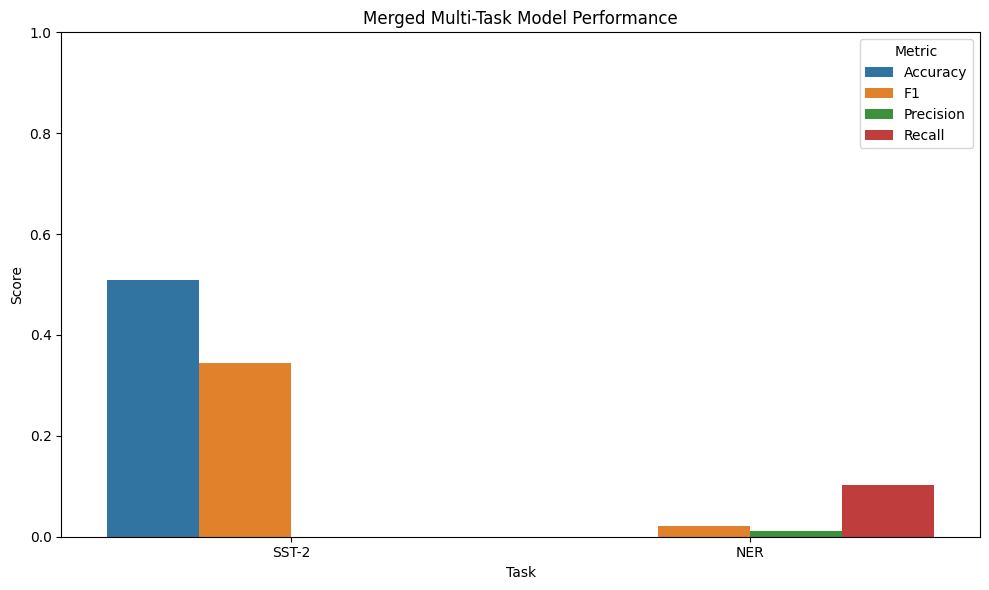

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Wrap metrics into a DataFrame
metrics_df = pd.DataFrame([
    {"Task": "SST-2", "Metric": "Accuracy", "Score": sst2_metrics["accuracy"]},
    {"Task": "SST-2", "Metric": "F1", "Score": sst2_metrics["f1"]},
    {"Task": "NER", "Metric": "F1", "Score": float(ner_metrics["overall_f1"])},
    {"Task": "NER", "Metric": "Precision", "Score": float(ner_metrics["overall_precision"])},
    {"Task": "NER", "Metric": "Recall", "Score": float(ner_metrics["overall_recall"])},
])

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_df, x="Task", y="Score", hue="Metric")
plt.title("Merged Multi-Task Model Performance")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.tight_layout()
plt.show()

# Example

In [28]:
sentence = "I really enjoyed the movie. It was fantastic!"

inputs = tokenizer(sentence, return_tensors="pt", padding=True, truncation=True)
device = next(model.parameters()).device  # ✅ Get model's device
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    logits = model(**inputs, task="sst2")  # ✅ Pass task as argument
    pred = torch.argmax(logits, dim=1).item()

label_map = {0: "Negative", 1: "Positive"}
print(f"Sentence: {sentence}")
print(f"Predicted Sentiment: {label_map[pred]}")

Sentence: I hate the movie. It was not good!
Predicted Sentiment: Positive


In [26]:
sentence = "Barack Obama was born in Hawaii."

# Tokenize the sentence
ner_inputs = tokenizer(sentence, return_tensors="pt", padding=True, truncation=True, is_split_into_words=False)
device = next(model.parameters()).device
ner_inputs = {k: v.to(device) for k, v in ner_inputs.items()}

# Run prediction
with torch.no_grad():
    logits = model(**ner_inputs, task="ner")  # ✅ task="ner" for token-level head
    predictions = torch.argmax(logits, dim=2)

# Convert token IDs back to words
input_ids = ner_inputs["input_ids"][0].tolist()
tokens = tokenizer.convert_ids_to_tokens(input_ids)
pred_ids = predictions[0].tolist()

# Define label mapping (adjust based on your label IDs)
id2label = {
    0: "O", 1: "B-LOC", 2: "I-LOC",
    3: "B-PER", 4: "I-PER",
    5: "B-ORG", 6: "I-ORG",
    7: "B-MISC", 8: "I-MISC"
}

# Print predicted entities (skip special tokens)
print(f"Sentence: {sentence}")
print("Predicted Entities:")
for token, pred in zip(tokens, pred_ids):
    if token not in tokenizer.all_special_tokens:
        print(f"{token}: {id2label.get(pred, 'O')}")

Sentence: Barack Obama was born in Hawaii.
Predicted Entities:
barack: B-LOC
obama: B-LOC
was: B-LOC
born: B-LOC
in: B-LOC
hawaii: B-LOC
.: B-LOC
